# Préparation des données de consommation éCO2mix (2012–2025)

**Objectif :** préparer une série horaire de consommation électrique nationale pour prévoir les 24 heures du jour J+1, avec les informations disponibles à 14 h le jour J.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

dossier_data = Path("data")
fichiers = sorted(dossier_data.glob("*.xls"))
if not fichiers:
    raise FileNotFoundError(
        f"Aucun fichier .xls trouvé dans {dossier_data.resolve()}. "
        "Vérifie le dossier et l'extension des fichiers."
    )

print(f"{len(fichiers)} fichiers trouvés dans {dossier_data.resolve()}")
for f in fichiers:
    print(f.name, f.stat().st_size, "octets")

14 fichiers trouvés dans C:\Users\pC\Downloads\projet serie temporelle\data
eCO2mix_RTE_Annuel-Definitif_2012.xls 4664150 octets
eCO2mix_RTE_Annuel-Definitif_2013.xls 4870747 octets
eCO2mix_RTE_Annuel-Definitif_2014.xls 4848259 octets
eCO2mix_RTE_Annuel-Definitif_2015.xls 4856640 octets
eCO2mix_RTE_Annuel-Definitif_2016.xls 4860550 octets
eCO2mix_RTE_Annuel-Definitif_2017.xls 4865215 octets
eCO2mix_RTE_Annuel-Definitif_2018.xls 4851128 octets
eCO2mix_RTE_Annuel-Definitif_2019.xls 5200552 octets
eCO2mix_RTE_Annuel-Definitif_2020.xls 5176171 octets
eCO2mix_RTE_Annuel-Definitif_2021.xls 5039011 octets
eCO2mix_RTE_Annuel-Definitif_2022.xls 5098040 octets
eCO2mix_RTE_Annuel-Definitif_2023.xls 5145595 octets
eCO2mix_RTE_Annuel-Definitif_2024.xls 5376186 octets
eCO2mix_RTE_Annuel-Definitif_2025.xls 5567163 octets


In [2]:
parts = []
for f in fichiers:
    d = pd.read_csv(f, sep="\t", encoding="cp1252", index_col=False, na_values=["ND"])
    d.columns = d.columns.str.strip()
    d["fichier_source"] = f.name
    parts.append(d)

source = pd.concat(parts, ignore_index=True)
print("Dimensions brutes :", source.shape)
print("\nColonnes :")
print(source.columns.tolist())
display(source.head())

Dimensions brutes : (490958, 41)

Colonnes :
['Périmètre', 'Nature', 'Date', 'Heures', 'Consommation', 'Prévision J-1', 'Prévision J', 'Fioul', 'Charbon', 'Gaz', 'Nucléaire', 'Eolien', 'Solaire', 'Hydraulique', 'Pompage', 'Bioénergies', 'Ech. physiques', 'Taux de Co2', 'Ech. comm. Angleterre', 'Ech. comm. Espagne', 'Ech. comm. Italie', 'Ech. comm. Suisse', 'Ech. comm. Allemagne-Belgique', 'Fioul - TAC', 'Fioul - Cogén.', 'Fioul - Autres', 'Gaz - TAC', 'Gaz - Cogén.', 'Gaz - CCG', 'Gaz - Autres', 'Hydraulique - Fil de l?eau + éclusée', 'Hydraulique - Lacs', 'Hydraulique - STEP turbinage', 'Bioénergies - Déchets', 'Bioénergies - Biomasse', 'Bioénergies - Biogaz', 'fichier_source', 'Stockage batterie', 'Déstockage batterie', 'Eolien terrestre', 'Eolien offshore']


,Périmètre,Nature,Date,Heures,Consommation,Prévision J-1,Prévision J,Fioul,Charbon,Gaz,Nucléaire,Eolien,Solaire,Hydraulique,Pompage,Bioénergies,Ech. physiques,Taux de Co2,Ech. comm. Angleterre,Ech. comm. Espagne,Ech. comm. Italie,Ech. comm. Suisse,Ech. comm. Allemagne-Belgique,Fioul - TAC,Fioul - Cogén.,Fioul - Autres,Gaz - TAC,Gaz - Cogén.,Gaz - CCG,Gaz - Autres,Hydraulique - Fil de l?eau + éclusée,Hydraulique - Lacs,Hydraulique - STEP turbinage,Bioénergies - Déchets,Bioénergies - Biomasse,Bioénergies - Biogaz,fichier_source,Stockage batterie,Déstockage batterie,Eolien terrestre,Eolien offshore
0,France,Données définitives,2012-01-01,00:00,58315.0,58200.0,58200.0,492.0,25.0,3816.0,52697.0,3588.0,0.0,7922.0,-1139.0,719.0,-9806.0,33.0,-1750.0,-1200.0,-862.0,-2625.0,-2940.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,eCO2mix_RTE_Annuel-Definitif_2012.xls,NaN,NaN,NaN,NaN
1,France,Données définitives,2012-01-01,00:15,NaN,57700.0,57550.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,eCO2mix_RTE_Annuel-Definitif_2012.xls,NaN,NaN,NaN,NaN
2,France,Données définitives,2012-01-01,00:30,58315.0,57200.0,56900.0,492.0,25.0,3816.0,52697.0,3588.0,0.0,7922.0,-1139.0,719.0,-9806.0,33.0,-1750.0,-1200.0,-862.0,-2625.0,-2940.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,eCO2mix_RTE_Annuel-Definitif_2012.xls,NaN,NaN,NaN,NaN
3,France,Données définitives,2012-01-01,00:45,NaN,56200.0,56000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,eCO2mix_RTE_Annuel-Definitif_2012.xls,NaN,NaN,NaN,NaN
4,France,Données définitives,2012-01-01,01:00,56231.0,55200.0,55100.0,492.0,25.0,3834.0,51747.0,3536.0,0.0,7598.0,-1730.0,721.0,-9993.0,34.0,-1750.0,-1400.0,-862.0,-2625.0,-2714.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,eCO2mix_RTE_Annuel-Definitif_2012.xls,NaN,NaN,NaN,NaN


Les fichiers sont réunis dans un seul tableau et le nom du fichier source est conservé pour faciliter la traçabilité.

In [3]:
colonnes_a_examiner = [
    c for c in ["Périmètre", "Nature", "Date", "Heures", "Consommation"]
    if c in source.columns
]
display(source[colonnes_a_examiner].head(12))

print("\nTypes :")
print(source[colonnes_a_examiner].dtypes)

for c in ["Périmètre", "Nature"]:
    if c in source.columns:
        print(f"\nValeurs de {c} (10 premières modalités) :")
        print(source[c].value_counts(dropna=False).head(10).to_string())

print("\nValeurs manquantes dans les colonnes examinées :")
print(source[colonnes_a_examiner].isna().sum().to_string())

,Périmètre,Nature,Date,Heures,Consommation
0,France,Données définitives,2012-01-01,00:00,58315.0
1,France,Données définitives,2012-01-01,00:15,NaN
2,France,Données définitives,2012-01-01,00:30,58315.0
3,France,Données définitives,2012-01-01,00:45,NaN
4,France,Données définitives,2012-01-01,01:00,56231.0
5,France,Données définitives,2012-01-01,01:15,NaN
6,France,Données définitives,2012-01-01,01:30,56075.0
7,France,Données définitives,2012-01-01,01:45,NaN
8,France,Données définitives,2012-01-01,02:00,55532.0
9,France,Données définitives,2012-01-01,02:15,NaN



Types :
Périmètre        object
Nature           object
Date             object
Heures           object
Consommation    float64
dtype: object

Valeurs de Périmètre (10 premières modalités) :
Périmètre
France                                                                                                                                                            490944
RTE ne pourra être tenu responsable de l'usage qui pourrait être fait des données mises à disposition, ni en cas de prévisions qui se révèleraient imprécises.        14

Valeurs de Nature (10 premières modalités) :
Nature
Données définitives    490944
NaN                        14

Valeurs manquantes dans les colonnes examinées :
Périmètre            0
Nature              14
Date                14
Heures              14
Consommation    245486


Les lignes sans date ou heure exploitable sont retirées et un horodatage est construit.

In [4]:
# Retirer uniquement les lignes de pied de fichier sans date/heure.
df = source.dropna(subset=["Date", "Heures"]).copy()
df["horodatage_source"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Heures"].astype(str),
    errors="coerce"
)
df = df.dropna(subset=["horodatage_source"]).sort_values("horodatage_source")
for c in ["Consommation", "Prévision J-1", "Prévision J"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("Lignes de pied de fichier retirées :", len(source) - len(df))
print("Période :", df["horodatage_source"].min(), "->", df["horodatage_source"].max())
print("Horodatages dupliqués :", df["horodatage_source"].duplicated().sum())
print("Périmètres :", df["Périmètre"].value_counts(dropna=False).to_dict())
print("Natures :", df["Nature"].value_counts(dropna=False).to_dict())

Lignes de pied de fichier retirées : 14
Période : 2012-01-01 00:00:00 -> 2025-12-31 23:45:00
Horodatages dupliqués : 0
Périmètres : {'France': 490944}
Natures : {'Données définitives': 490944}


In [5]:
print(df["horodatage_source"].dt.year.value_counts().sort_index().to_string())

horodatage_source
2012    35136
2013    35040
2014    35040
2015    35040
2016    35136
2017    35040
2018    35040
2019    35040
2020    35136
2021    35040
2022    35040
2023    35040
2024    35136
2025    35040


Les données couvrent chaque année de 2012 à 2025. Les années bissextiles contiennent davantage de mesures, ce qui est normal.

In [6]:
print(df.groupby(df["horodatage_source"].dt.minute)["Consommation"].count())

horodatage_source
0     122736
15         0
30    122736
45         0
Name: Consommation, dtype: int64


Les mesures utiles sont disponibles toutes les 30 minutes (:00 et :30). Pour construire le dataset horaire, on choisira directement la mesure prise à :00, sans faire la moyenne avec celle de :30.

In [7]:
# Garder uniquement les lignes où la consommation est renseignée.
df = df.dropna(subset=["Consommation"]).copy()
df = df[
    [
        "Date",
        "Heures",
        "horodatage_source",
        "Consommation",
        "Prévision J-1",
        "Prévision J"
    ]
].copy()

conso_demi_horaire = df.set_index("horodatage_source")[[
    "Consommation", "Prévision J-1", "Prévision J"
]].copy()

print(len(df), "mesures")
display(df.head())


245472 mesures


,Date,Heures,horodatage_source,Consommation,Prévision J-1,Prévision J
0,2012-01-01,00:00,2012-01-01 00:00:00,58315.0,58200.0,58200.0
2,2012-01-01,00:30,2012-01-01 00:30:00,58315.0,57200.0,56900.0
4,2012-01-01,01:00,2012-01-01 01:00:00,56231.0,55200.0,55100.0
6,2012-01-01,01:30,2012-01-01 01:30:00,56075.0,56000.0,55400.0
8,2012-01-01,02:00,2012-01-01 02:00:00,55532.0,56000.0,55000.0


Après retrait des consommations manquantes, le tableau contient les mesures utiles et les deux colonnes de prévision.

In [8]:
print("Horodatages dupliqués :", df["horodatage_source"].duplicated().sum())

intervalles = df["horodatage_source"].sort_values().diff().dropna()
print("\nIntervalles entre horodatages successifs :")
print(intervalles.value_counts().head(10).to_string())

intervalles_non_15min = intervalles[intervalles != pd.Timedelta(minutes=15)]
print("\nIntervalles différents de 15 minutes :", len(intervalles_non_15min))
display(intervalles_non_15min.head(10))


Horodatages dupliqués : 0

Intervalles entre horodatages successifs :
horodatage_source
0 days 00:30:00    245471

Intervalles différents de 15 minutes : 245471


2    0 days 00:30:00
4    0 days 00:30:00
6    0 days 00:30:00
8    0 days 00:30:00
10   0 days 00:30:00
12   0 days 00:30:00
14   0 days 00:30:00
16   0 days 00:30:00
18   0 days 00:30:00
20   0 days 00:30:00
Name: horodatage_source, dtype: timedelta64[ns]

Aucun horodatage dupliqué n’est détecté et les mesures successives sont espacées de 30 minutes. Le code compare les intervalles à 15 minutes : les écarts affichés correspondent donc à la fréquence réelle de 30 minutes, pas nécessairement à des anomalies.

In [9]:
# Examiner les zéros et valeurs manquantes des colonnes de prévision.
for c in ["Prévision J-1", "Prévision J"]:
    if c in df.columns:
        print(f"\n{c}")
        print("Valeurs manquantes :", df[c].isna().sum())
        print("Valeurs égales à zéro :", (df[c] == 0).sum())
        print("Valeurs négatives :", (df[c] < 0).sum())
        display(df.loc[df[c].eq(0), ["horodatage_source", c]].head(10))



Prévision J-1
Valeurs manquantes : 0
Valeurs égales à zéro : 0
Valeurs négatives : 0


,horodatage_source,Prévision J-1



Prévision J
Valeurs manquantes : 0
Valeurs égales à zéro : 141
Valeurs négatives : 0


,horodatage_source,Prévision J
112421,2015-03-17 00:30:00,0.0
112423,2015-03-17 01:00:00,0.0
112425,2015-03-17 01:30:00,0.0
112427,2015-03-17 02:00:00,0.0
112429,2015-03-17 02:30:00,0.0
112431,2015-03-17 03:00:00,0.0
112433,2015-03-17 03:30:00,0.0
112435,2015-03-17 04:00:00,0.0
112437,2015-03-17 04:30:00,0.0
112439,2015-03-17 05:00:00,0.0


Un zéro dans la colonne des prévisions semble incohérent, car la consommation nationale est de l’ordre de 50 000 MW. Pour les jours concernés, on considère donc que la prévision est manquante et on la remplace par NaN, sans chercher à la reconstituer.

Par ailleurs, même si une prévision est valide, elle ne peut être utilisée comme variable explicative que si elle était effectivement disponible à 14 h le jour J, au moment où l’on cherche à prévoir la consommation du lendemain (J+1). Il faut donc vérifier son heure de publication avant de l’utiliser.

In [10]:
# Remplacer par NaN les zéros de prévision, après vérification des résultats ci-dessus.

for c in ["Prévision J-1", "Prévision J"]:
    df[c] = df[c].replace(0, np.nan)
    conso_demi_horaire[c] = conso_demi_horaire[c].replace(0, np.nan)
print(df[["Prévision J-1", "Prévision J"]].isna().sum())


Prévision J-1      0
Prévision J      141
dtype: int64


In [11]:
y = conso_demi_horaire["Consommation"]
print(y.describe().round(0))
print("valeurs <= 0 :", (y <= 0).sum())
print("maximum :", y.idxmax(), y.max(), "| prévision J :", conso_demi_horaire.loc[y.idxmax(), "Prévision J"])
print("minimum :", y.idxmin(), y.min(), "| prévision J :", conso_demi_horaire.loc[y.idxmin(), "Prévision J"])


count    245472.0
mean      53003.0
std       11743.0
min       29124.0
25%       44140.0
50%       51220.0
75%       60820.0
max      102098.0
Name: Consommation, dtype: float64
valeurs <= 0 : 0
maximum : 2012-02-08 19:00:00 102098.0 | prévision J : 102700.0
minimum : 2020-05-10 07:00:00 29124.0 | prévision J : 29400.0


Le maximum et le minimum sont confirmés par la prévision RTE : ce sont de vraies valeurs extrêmes (grand froid, creux d'été/nuit), pas des erreurs. Un extrême n'est pas une erreur.

Pour trouver de **vraies erreurs**, on cherche les pics isolés : un point très éloigné de la moyenne de ses deux voisins.

In [12]:
ecart = y - (y.shift(1) + y.shift(-1)) / 2  # écart à la moyenne des voisins
top = pd.DataFrame({"conso": y, "écart": ecart.round(0), "écart %": (ecart / y * 100).round(1),
                    "prévision J": conso_demi_horaire["Prévision J"]})
top = top.reindex(ecart.abs().sort_values(ascending=False).index[:10])
top


,conso,écart,écart %,prévision J
horodatage_source,,,,
2022-01-10 10:00:00,81945.0,6498.0,7.9,75100.0
2022-01-10 10:30:00,75700.0,-3152.0,-4.2,75600.0
2022-01-10 09:30:00,75194.0,-3149.0,-4.2,74800.0
2012-02-21 19:00:00,80243.0,2651.0,3.3,80800.0
2012-02-20 19:00:00,80440.0,2645.0,3.3,80800.0
2020-04-13 20:30:00,38767.0,-2630.0,-6.8,40900.0
2012-02-22 19:00:00,78719.0,2546.0,3.2,77700.0
2013-02-19 19:00:00,78281.0,2504.0,3.2,79500.0
2014-02-24 19:00:00,68424.0,2462.0,3.6,69500.0


Le tableau repère les instants où la consommation s’écarte le plus de la moyenne de ses deux voisins. Ce classement sert à identifier des points à vérifier, mais ne suffit pas à prouver qu’il s’agit d’erreurs.

                     Consommation  Prévision J
horodatage_source                             
2022-01-10 08:30:00       74299.0      74200.0
2022-01-10 09:00:00       74741.0      74200.0
2022-01-10 09:30:00       75194.0      74800.0
2022-01-10 10:00:00       81945.0      75100.0
2022-01-10 10:30:00       75700.0      75600.0
2022-01-10 11:00:00       75758.0      75500.0
2022-01-10 11:30:00       76079.0      75700.0


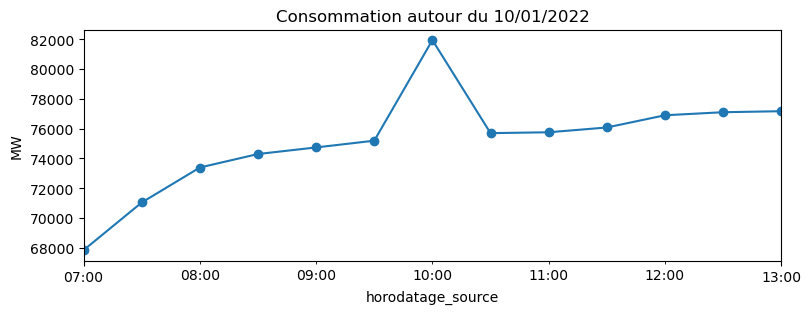

In [13]:
print(conso_demi_horaire.loc["2022-01-10 08:30":"2022-01-10 11:30", ["Consommation", "Prévision J"]])

conso_demi_horaire.loc["2022-01-10 07:00":"2022-01-10 13:00", "Consommation"].plot(
    marker="o", figsize=(9, 3), title="Consommation autour du 10/01/2022"
)
plt.ylabel("MW")
plt.show()


Exemple : le point du 10/01/2022 à 10:00 présente une hausse de consommation par rapport aux deux mesures voisines. Cette observation est à vérifier, mais elle ne suffit pas à conclure à une erreur dans les données.

In [14]:
# À une fréquence de 30 minutes, 48 mesures par date sont attendues si les horodatages
# suivent une convention à 24 h/jour 
par_jour = conso_demi_horaire["Consommation"].groupby(
    conso_demi_horaire.index.normalize()
).count()
print("Distribution du nombre de mesures renseignées par date :")
print(par_jour.value_counts().sort_index().to_string())

print("\nDates qui n'ont pas 48 mesures :")
display(par_jour[par_jour != 48].to_frame("nb_mesures"))

Distribution du nombre de mesures renseignées par date :
Consommation
48    5114

Dates qui n'ont pas 48 mesures :


,nb_mesures
horodatage_source,


Toutes les dates affichées possèdent 48 mesures de demi-heure dans ce fichier. 

In [15]:
# Examiner les derniers dimanches de mars et d'octobre 2025.
# Ces dates servent d'exemples à inspecter 
for date_exemple in ["2025-03-30", "2025-10-26"]:
    debut = pd.Timestamp(date_exemple)
    fin = debut + pd.Timedelta(hours=5)
    print(f"\n{date_exemple} :")
    display(conso_demi_horaire.loc[debut:fin, ["Consommation"]])


2025-03-30 :


,Consommation
horodatage_source,
2025-03-30 00:00:00,52144.0
2025-03-30 00:30:00,51361.0
2025-03-30 01:00:00,49203.0
2025-03-30 01:30:00,48415.0
2025-03-30 02:00:00,47832.0
2025-03-30 02:30:00,48415.0
2025-03-30 03:00:00,47832.0
2025-03-30 03:30:00,48397.0
2025-03-30 04:00:00,46396.0



2025-10-26 :


,Consommation
horodatage_source,
2025-10-26 00:00:00,47386.0
2025-10-26 00:30:00,46381.0
2025-10-26 01:00:00,44168.0
2025-10-26 01:30:00,43714.0
2025-10-26 02:00:00,43118.0
2025-10-26 02:30:00,42385.0
2025-10-26 03:00:00,40960.0
2025-10-26 03:30:00,38519.0
2025-10-26 04:00:00,38226.0


En heure légale française, le passage à l'heure d'été supprime une heure locale, tandis que le retour à l'heure d'hiver répète une heure locale. Ici, les horodatages sont sans fuseau horaire explicite.

In [16]:
# Vérifier la disponibilité des mesures prises à :00, qui seront utilisées dans le dataset horaire.
mesures_00 = conso_demi_horaire[
    conso_demi_horaire.index.minute == 0
]["Consommation"]

print("Nombre de mesures prises à :00 :", len(mesures_00))
print("Horodatages dupliqués à :00 :", mesures_00.index.duplicated().sum())
print("Mesures manquantes à :00 :", mesures_00.isna().sum())
display(mesures_00.head(12).to_frame("consommation_MW"))

Nombre de mesures prises à :00 : 122736
Horodatages dupliqués à :00 : 0
Mesures manquantes à :00 : 0


,consommation_MW
horodatage_source,
2012-01-01 00:00:00,58315.0
2012-01-01 01:00:00,56231.0
2012-01-01 02:00:00,55532.0
2012-01-01 03:00:00,52496.0
2012-01-01 04:00:00,49161.0
2012-01-01 05:00:00,46656.0
2012-01-01 06:00:00,45827.0
2012-01-01 07:00:00,45580.0
2012-01-01 08:00:00,45770.0


Le dataset horaire utilisera uniquement la mesure enregistrée à chaque heure pile (:00). La mesure de :30 ne sera pas moyennée avec celle de :00 ; les heures sans valeur à :00 resteront manquantes plutôt que d'être estimées.

In [17]:
# Construire le dataset horaire en conservant directement la mesure prise à :00.
dataset_final = conso_demi_horaire.loc[
    conso_demi_horaire.index.minute == 0, ["Consommation"]
].copy()

dataset_final = dataset_final.rename(
    columns={"Consommation": "consommation_MW"}
)
dataset_final.index.name = "horodatage"

# Vérifier les doublons et les valeurs manquantes, sans créer de valeur artificielle.
print("Nombre de lignes :", len(dataset_final))
print("Horodatages dupliqués :", dataset_final.index.duplicated().sum())
print("Consommations manquantes :", dataset_final["consommation_MW"].isna().sum())

# Exporter le dataset pour la suite du projet.
dossier_sortie = Path("data_prepared")
dossier_sortie.mkdir(parents=True, exist_ok=True)

dataset_export = dataset_final.reset_index()
chemin_sortie = dossier_sortie / "consommation_horaire_eco2mix_2012_2025.csv"
dataset_export.to_csv(chemin_sortie, index=False, encoding="utf-8")

print("Dataset enregistré :", chemin_sortie.resolve())
display(dataset_export.head())

Nombre de lignes : 122736
Horodatages dupliqués : 0
Consommations manquantes : 0
Dataset enregistré : C:\Users\pC\Downloads\projet serie temporelle\data_prepared\consommation_horaire_eco2mix_2012_2025.csv


,horodatage,consommation_MW
0,2012-01-01 00:00:00,58315.0
1,2012-01-01 01:00:00,56231.0
2,2012-01-01 02:00:00,55532.0
3,2012-01-01 03:00:00,52496.0
4,2012-01-01 04:00:00,49161.0


Le fichier final contient une ligne par heure pile, avec la valeur de consommation directement mesurée à :00 en MW. Les variables calendaires, les données météo et la validation temporelle seront préparées ensuite.